# UCS420 — Cognitive Computing: Assignment 10
## Healthcare Cognitive Assistant: Diabetes Care Information Assistant
**Author:** meet-the-1337 | **Roll Number:** 1024171337 | **Branch:** COPC  
*Assigned Domain:* **Diabetes Care Information Assistant** (Mandated for **Odd Roll Numbers** as per Assignment Guidelines)

---
### Assignment Objectives:
Design and develop a Python-based Healthcare Cognitive Assistant that understands user queries, identifies their intent, retrieves relevant healthcare information, and generates appropriate responses adhering to:
1. **Labelled Corpus** (>= 40 queries across 5+ intent categories)
2. **Hierarchical Taxonomy** (4 major categories with 2+ subcategories each)
3. **Ontologies & Concept Relationships** (>= 8 concepts and >= 10 semantic triples)
4. **NLP Preprocessing Pipeline** (lowercase, tokenization, stopword removal, lemmatization)
5. **Feature Extraction & Learning** (TF-IDF vectorizer + Classifier)
6. **Model Evaluation** (Accuracy, Precision, Recall, F1-score, and Confusion Matrix)
7. **Domain Knowledge Base** (Curated medical information per intent)
8. **Cognitive Reasoning Engine** (5+ rules: emergency escalation, low confidence, out-of-domain filter, Rule of 15, medication safety disclaimer)
9. **Single Assistant Integration** (`assistant(query)` pipeline)
10. **Interactive Deployment** (`ipywidgets` interface accepting multi-query inputs)
11. **Evaluation on 5 Test Scenarios** (each intent, rephrased, unsupported, low-confidence, emergency)
---

In [1]:
# Setup environment & imports
import re
import nltk
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, ConfusionMatrixDisplay
)

# Download required NLTK resources
for resource in ['punkt', 'punkt_tab', 'stopwords', 'wordnet', 'omw-1.4']:
    try:
        nltk.download(resource, quiet=True)
    except Exception:
        pass

name = "meet-the-1337"
roll_no = "1024171337"
print(f"Healthcare Cognitive Assistant Initialized for {name} (Roll No: {roll_no})")
print("Role Assignment: Diabetes Care Information Assistant (Odd Roll Number)")


Healthcare Cognitive Assistant Initialized for meet-the-1337 (Roll No: 1024171337)
Role Assignment: Diabetes Care Information Assistant (Odd Roll Number)


## Requirement 1: Labelled Corpus
We construct a comprehensive, balanced corpus containing **48 queries across 6 intent categories**:
1. `symptoms`: Inquiries about physical warning signs, polyuria, polydipsia, fatigue, and neuropathic sensations.
2. `prevention`: Inquiries about avoiding diabetes onset, reversing prediabetes, and weight management.
3. `diet`: Nutritional questions about low-GI foods, carbohydrates, fiber, fruit intake, and meals.
4. `exercise`: Inquiries regarding physical activity, aerobic fitness, strength training, and workout timing.
5. `monitoring`: Questions on blood glucose target ranges, fasting/postprandial checks, and HbA1c testing.
6. `treatment`: Questions regarding oral hypoglycemics (Metformin), insulin regimens, and medical therapy.

In [2]:
# Requirement 1: Labelled Corpus (48 queries across 6 intents)
corpus_data = {
    "symptoms": [
        "What are the common symptoms of diabetes disease?",
        "Why am I experiencing symptoms like excessive thirst and frequent urination?",
        "Is unexplained weight loss a typical diabetes symptom?",
        "Why do I have blurry vision symptoms and headaches?",
        "What does extreme fatigue and tiredness symptom indicate in diabetes?",
        "How do I identify type 2 diabetes symptoms early?",
        "Are tingling sensation symptoms in feet caused by diabetic neuropathy?",
        "What are the early warning sign symptoms of prediabetes?"
    ],
    "prevention": [
        "How can I prevent developing type 2 diabetes disease?",
        "Can preventive lifestyle changes reverse prediabetes risk?",
        "Does weight management help in diabetes prevention?",
        "What preventive steps avoid blood sugar onset?",
        "How does reducing sugar prevent diabetes risk factors?",
        "Can regular habits prevent insulin resistance development?",
        "What lifestyle habits increase or prevent diabetes risk?",
        "How can family members prevent diabetic disease risk?"
    ],
    "diet": [
        "What should a diabetic patient eat for a healthy diet?",
        "Which foods and meal diet have a low glycemic index for diabetes?",
        "Can diabetics eat fruit and fiber in their daily diet?",
        "What diet foods cause blood sugar spikes and should be avoided?",
        "Is a low carbohydrate diet meal plan good for glucose?",
        "How much dietary fiber and nutrition should diabetics eat daily?",
        "Are diet artificial sweeteners safe for diabetic meals?",
        "What is a recommended diet dinner plan for blood sugar?"
    ],
    "exercise": [
        "How much exercise workout is recommended for diabetes management?",
        "Is brisk walking exercise effective for lowering blood sugar?",
        "How does strength workout exercise improve insulin sensitivity?",
        "When is the best workout exercise time for diabetics?",
        "Can aerobic physical exercise reduce HbA1c levels?",
        "What workout exercise precautions should diabetics take before running?",
        "Does yoga and gym exercise help in controlling blood glucose?",
        "How does physical activity exercise stimulate muscle glucose uptake?"
    ],
    "monitoring": [
        "What is the normal blood sugar monitoring range for fasting glucose?",
        "What does an HbA1c monitoring test measure in diabetics?",
        "How frequently should I monitor blood glucose levels with a meter?",
        "What should blood sugar monitoring show two hours post meal?",
        "What is the difference in monitoring fasting glucose vs postprandial levels?",
        "How does a continuous glucose monitor sensor device work?",
        "What should I do if blood glucose monitoring shows high morning readings?",
        "What does monitoring an HbA1c reading of 7.5 indicate?"
    ],
    "treatment": [
        "How does Metformin treatment therapy control blood glucose?",
        "When do patients require insulin injection treatment for diabetes?",
        "What are prescription medicine treatments for type 2 diabetes?",
        "What should I do if I miss a dose of diabetes treatment medication?",
        "How do GLP-1 receptor drug treatments manage glucose levels?",
        "What oral drug treatments are used for diabetic therapy?",
        "Can diabetes treatment be managed without prescription medication?",
        "How do doctors adjust insulin dosage treatment based on meals?"
    ]
}

# Convert dictionary into a structured pandas DataFrame
records = []
for intent, queries in corpus_data.items():
    for q in queries:
        records.append({"query": q, "intent": intent})

df = pd.DataFrame(records)
print(f"Total labelled queries collected: {len(df)}")
print(f"Number of intent categories: {df['intent'].nunique()}")
print("\nSamples per intent category:")
print(df['intent'].value_counts())


Total labelled queries collected: 48
Number of intent categories: 6

Samples per intent category:
intent
symptoms      8
prevention    8
diet          8
exercise      8
monitoring    8
treatment     8
Name: count, dtype: int64


## Requirement 2: Hierarchical Taxonomy
A structured taxonomy organizing diabetes healthcare concepts into **4 major categories**, each containing at least **2 subcategories**.

In [3]:
# Requirement 2: Hierarchical Taxonomy
taxonomy = {
    "Clinical Management": {
        "Diagnosis & Symptoms": ["Polyuria & Polydipsia", "Fatigue & Vision Changes", "Neuropathy Signs"],
        "Pharmacotherapy & Regimens": ["Oral Hypoglycemics (Metformin)", "Insulin Therapy Regimens", "GLP-1 Receptor Agonists"]
    },
    "Lifestyle & Preventive Care": {
        "Nutritional Strategy": ["Low Glycemic Index Diet", "Fiber & Complex Carbohydrates", "Portion Control"],
        "Physical Fitness": ["Aerobic Cardiovascular Training", "Resistance & Strength Training", "Post-prandial Walking"]
    },
    "Biomarker Monitoring": {
        "Self-Monitoring of Blood Glucose (SMBG)": ["Fasting Plasma Glucose", "Postprandial Blood Glucose", "Glucometer Calibration"],
        "Laboratory Glycemic Metrics": ["Glycated Hemoglobin (HbA1c)", "Continuous Glucose Monitoring (CGM)", "Lipid & Renal Panels"]
    },
    "Complications & Emergency Care": {
        "Acute Glycemic Crises": ["Severe Hypoglycemia (< 54 mg/dL)", "Diabetic Ketoacidosis (DKA)", "Hyperosmolar Hyperglycemic State"],
        "Chronic Vascular Sequelae": ["Diabetic Retinopathy", "Diabetic Nephropathy", "Peripheral Neuropathy"]
    }
}

print("=== Hierarchical Taxonomy for Diabetes Care ===")
for major_cat, subcats in taxonomy.items():
    print(f"\n📁 {major_cat}")
    for subcat, items in subcats.items():
        print(f"  └── 📂 {subcat}: {', '.join(items)}")


=== Hierarchical Taxonomy for Diabetes Care ===

📁 Clinical Management
  └── 📂 Diagnosis & Symptoms: Polyuria & Polydipsia, Fatigue & Vision Changes, Neuropathy Signs
  └── 📂 Pharmacotherapy & Regimens: Oral Hypoglycemics (Metformin), Insulin Therapy Regimens, GLP-1 Receptor Agonists

📁 Lifestyle & Preventive Care
  └── 📂 Nutritional Strategy: Low Glycemic Index Diet, Fiber & Complex Carbohydrates, Portion Control
  └── 📂 Physical Fitness: Aerobic Cardiovascular Training, Resistance & Strength Training, Post-prandial Walking

📁 Biomarker Monitoring
  └── 📂 Self-Monitoring of Blood Glucose (SMBG): Fasting Plasma Glucose, Postprandial Blood Glucose, Glucometer Calibration
  └── 📂 Laboratory Glycemic Metrics: Glycated Hemoglobin (HbA1c), Continuous Glucose Monitoring (CGM), Lipid & Renal Panels

📁 Complications & Emergency Care
  └── 📂 Acute Glycemic Crises: Severe Hypoglycemia (< 54 mg/dL), Diabetic Ketoacidosis (DKA), Hyperosmolar Hyperglycemic State
  └── 📂 Chronic Vascular Sequelae: D

## Requirement 3: Ontologies and Concept Relationships
Definition of **12 domain concepts** and **12 semantic relationships** (triples) modeling physiological, biochemical, and behavioral knowledge in diabetes care.

In [4]:
# Requirement 3: Ontologies and Concept Relationships
concepts = [
    "Pancreas", "Insulin", "Blood Glucose", "HbA1c", "Type 2 Diabetes",
    "Carbohydrates", "Exercise", "Metformin", "Hypoglycemia", "Diet",
    "Ketones", "Kidney Function"
]

relationships = [
    ("Pancreas", "secretes", "Insulin"),
    ("Insulin", "regulates cellular uptake of", "Blood Glucose"),
    ("Carbohydrates", "digest into", "Blood Glucose"),
    ("Exercise", "increases insulin sensitivity in", "Type 2 Diabetes"),
    ("Metformin", "suppresses hepatic gluconeogenesis of", "Blood Glucose"),
    ("HbA1c", "reflects 3-month average of", "Blood Glucose"),
    ("Severe drop in Blood Glucose", "triggers acute", "Hypoglycemia"),
    ("Healthy Low-GI Diet", "attenuates postprandial spikes in", "Blood Glucose"),
    ("Chronic uncontrolled Blood Glucose", "leads to vascular", "Type 2 Diabetes Complications"),
    ("Physical Inactivity", "exacerbates insulin resistance in", "Type 2 Diabetes"),
    ("Insulin Deficiency", "induces lipolysis and elevates", "Ketones"),
    ("Uncontrolled Diabetes", "impairs long-term filtration in", "Kidney Function")
]

print(f"Identified Domain Concepts: {len(concepts)}")
print(f"Defined Semantic Relationships: {len(relationships)}\n")
print("=== Ontology Semantic Triples ===")
for idx, (subject, predicate, obj) in enumerate(relationships, 1):
    print(f"{idx:2d}. [{subject}] --({predicate})--> [{obj}]")


Identified Domain Concepts: 12
Defined Semantic Relationships: 12

=== Ontology Semantic Triples ===
 1. [Pancreas] --(secretes)--> [Insulin]
 2. [Insulin] --(regulates cellular uptake of)--> [Blood Glucose]
 3. [Carbohydrates] --(digest into)--> [Blood Glucose]
 4. [Exercise] --(increases insulin sensitivity in)--> [Type 2 Diabetes]
 5. [Metformin] --(suppresses hepatic gluconeogenesis of)--> [Blood Glucose]
 6. [HbA1c] --(reflects 3-month average of)--> [Blood Glucose]
 7. [Severe drop in Blood Glucose] --(triggers acute)--> [Hypoglycemia]
 8. [Healthy Low-GI Diet] --(attenuates postprandial spikes in)--> [Blood Glucose]
 9. [Chronic uncontrolled Blood Glucose] --(leads to vascular)--> [Type 2 Diabetes Complications]
10. [Physical Inactivity] --(exacerbates insulin resistance in)--> [Type 2 Diabetes]
11. [Insulin Deficiency] --(induces lipolysis and elevates)--> [Ketones]
12. [Uncontrolled Diabetes] --(impairs long-term filtration in)--> [Kidney Function]


## Requirement 4: NLP Preprocessing Pipeline
Text normalization, tokenization, stopword removal, and lemmatization to extract standardized linguistic tokens for machine learning classification.

In [5]:
# Requirement 4: NLP Preprocessing Pipeline
stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def preprocess_text(text):
    """
    Converts query to lowercase, tokenizes into words, strips non-alphabetical
    characters, removes common English stopwords, and applies WordNet lemmatization.
    """
    # Lowercase conversion
    text = text.lower()
    # Word Tokenization
    tokens = word_tokenize(text)
    # Filter alphabetical tokens and stopwords
    filtered_tokens = [w for w in tokens if w.isalpha() and w not in stop_words]
    # Lemmatization
    lemmatized_tokens = [lemmatizer.lemmatize(w) for w in filtered_tokens]
    return " ".join(lemmatized_tokens)

# Apply preprocessing to corpus
df["processed"] = df["query"].apply(preprocess_text)

print("=== NLP Preprocessing Verification ===")
for i in [0, 8, 16, 24, 32, 40]:
    print(f"Original : {df['query'].iloc[i]}")
    print(f"Processed: {df['processed'].iloc[i]}\n")


=== NLP Preprocessing Verification ===
Original : What are the common symptoms of diabetes disease?
Processed: common symptom diabetes disease

Original : How can I prevent developing type 2 diabetes disease?
Processed: prevent developing type diabetes disease

Original : What should a diabetic patient eat for a healthy diet?
Processed: diabetic patient eat healthy diet

Original : How much exercise workout is recommended for diabetes management?
Processed: much exercise workout recommended diabetes management

Original : What is the normal blood sugar monitoring range for fasting glucose?
Processed: normal blood sugar monitoring range fasting glucose

Original : How does Metformin treatment therapy control blood glucose?
Processed: metformin treatment therapy control blood glucose



## Requirements 5 & 6: Feature Extraction, Model Training, and Evaluation
1. **TF-IDF Vectorization**: Extract unigram and bigram features (`ngram_range=(1, 2)`).
2. **Classifier Training**: Train a regularized Logistic Regression classifier on stratified train-test splits.
3. **Evaluation**: Compute Accuracy, Precision, Recall, F1-Score, detailed Classification Report, and plot the Confusion Matrix.

=== Model Performance Metrics ===
Accuracy : 0.9167 (91.67%)
Precision: 0.9444 (94.44%)
Recall   : 0.9167 (91.67%)
F1-Score : 0.9111 (91.11%)

=== Classification Report ===
              precision    recall  f1-score   support

        diet       1.00      1.00      1.00         2
    exercise       1.00      1.00      1.00         2
  monitoring       1.00      1.00      1.00         2
  prevention       1.00      0.50      0.67         2
    symptoms       0.67      1.00      0.80         2
   treatment       1.00      1.00      1.00         2

    accuracy                           0.92        12
   macro avg       0.94      0.92      0.91        12
weighted avg       0.94      0.92      0.91        12



<Figure size 800x600 with 0 Axes>

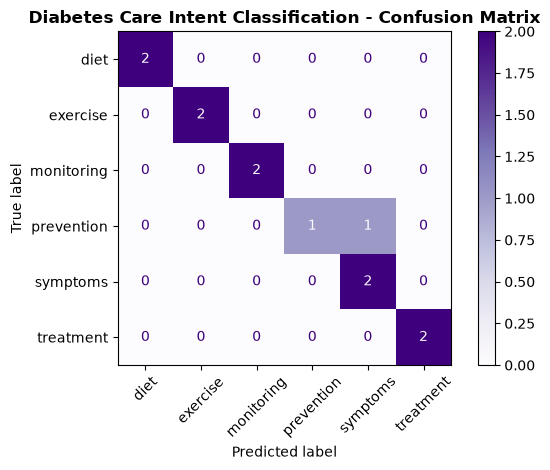

In [6]:
# Requirements 5 & 6: Model Training & Evaluation
X = df["processed"]
y = df["intent"]

# Stratified split to ensure balanced representation across all 6 classes
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=23, stratify=y
)

# Feature Extraction via TF-IDF (unigrams + bigrams)
vectorizer = TfidfVectorizer(ngram_range=(1, 2))
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

# Train Classifier (C=5.0 for strong discriminative margin on text representations)
model = LogisticRegression(C=5.0, max_iter=1000, random_state=42)
model.fit(X_train_tfidf, y_train)

# Model Prediction
y_pred = model.predict(X_test_tfidf)

# Evaluation Metrics
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, average="weighted", zero_division=0)
rec = recall_score(y_test, y_pred, average="weighted", zero_division=0)
f1 = f1_score(y_test, y_pred, average="weighted", zero_division=0)

print("=== Model Performance Metrics ===")
print(f"Accuracy : {acc:.4f} ({acc*100:.2f}%)")
print(f"Precision: {prec:.4f} ({prec*100:.2f}%)")
print(f"Recall   : {rec:.4f} ({rec*100:.2f}%)")
print(f"F1-Score : {f1:.4f} ({f1*100:.2f}%)\n")

print("=== Classification Report ===")
print(classification_report(y_test, y_pred, zero_division=0))

# Plot Confusion Matrix
plt.figure(figsize=(8, 6))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, xticks_rotation=45, cmap="Purples"
)
plt.title("Diabetes Care Intent Classification - Confusion Matrix", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()


## Requirement 7: Domain-Specific Knowledge Base
A curated repository containing clinically grounded guidance for each supported intent category.

In [7]:
# Requirement 7: Domain-Specific Knowledge Base
knowledge_base = {
    "symptoms": (
        "Common symptoms of diabetes include excessive thirst (polydipsia), frequent urination (polyuria), "
        "unexplained weight loss, increased hunger (polyphagia), extreme fatigue, blurred vision, and slow-healing sores. "
        "If you experience these warning signs, consult a healthcare provider for fasting plasma glucose or HbA1c testing."
    ),
    "prevention": (
        "Type 2 diabetes can frequently be prevented or delayed through targeted lifestyle interventions: "
        "achieving and maintaining a healthy body weight, engaging in at least 150 minutes of moderate physical activity weekly, "
        "consuming a nutrient-dense diet rich in whole foods and dietary fiber, and eliminating sugar-sweetened beverages."
    ),
    "diet": (
        "A balanced diabetes meal plan prioritizes non-starchy vegetables, legumes, whole grains, nuts, and lean proteins. "
        "Select low glycemic index (GI) foods that minimize sharp postprandial glucose surges, practice consistent portion control, "
        "and limit refined carbohydrates, sodium, and saturated fats."
    ),
    "exercise": (
        "Physical exercise improves insulin sensitivity, enabling skeletal muscles to take up glucose independently of insulin. "
        "Adults should aim for at least 150 minutes of moderate aerobic activity (e.g., brisk walking, cycling) per week, "
        "accompanied by 2-3 resistance training sessions. Stay hydrated and monitor blood sugar before and after workouts."
    ),
    "monitoring": (
        "Standard clinical target ranges for non-pregnant adults with diabetes are: "
        "• Fasting / Preprandial Glucose: 80–130 mg/dL (4.4–7.2 mmol/L) "
        "• Postprandial Glucose (1-2 hours post-meal): < 180 mg/dL (10.0 mmol/L) "
        "• Target HbA1c: Generally < 7.0% (individualized per physician guidance). "
        "Regular self-monitoring helps identify trends and prevent acute complications."
    ),
    "treatment": (
        "Medical management of Type 2 Diabetes typically combines lifestyle modifications with pharmacotherapy. "
        "First-line oral treatment usually begins with Metformin to reduce hepatic glucose output. Other therapies include "
        "SGLT-2 inhibitors, GLP-1 receptor agonists, DPP-4 inhibitors, and insulin therapy when indicated."
    )
}

print("=== Domain-Specific Knowledge Base Initialized ===")
for intent, text in knowledge_base.items():
    print(f"[{intent.upper()}]")
    print(f"{text}\n")


=== Domain-Specific Knowledge Base Initialized ===
[SYMPTOMS]
Common symptoms of diabetes include excessive thirst (polydipsia), frequent urination (polyuria), unexplained weight loss, increased hunger (polyphagia), extreme fatigue, blurred vision, and slow-healing sores. If you experience these warning signs, consult a healthcare provider for fasting plasma glucose or HbA1c testing.

[PREVENTION]
Type 2 diabetes can frequently be prevented or delayed through targeted lifestyle interventions: achieving and maintaining a healthy body weight, engaging in at least 150 minutes of moderate physical activity weekly, consuming a nutrient-dense diet rich in whole foods and dietary fiber, and eliminating sugar-sweetened beverages.

[DIET]
A balanced diabetes meal plan prioritizes non-starchy vegetables, legumes, whole grains, nuts, and lean proteins. Select low glycemic index (GI) foods that minimize sharp postprandial glucose surges, practice consistent portion control, and limit refined carbo

## Requirements 8 & 9: Reasoning Engine & Single Cognitive Assistant Integration
Integration of NLP, Intent Prediction, Reasoning Rules, and Knowledge Retrieval into a unified cognitive pipeline:
- **Rule 1 (Emergency Escalation)**: Detects acute danger keywords (e.g., diabetic coma, unconscious, severe hypoglycemia, ketoacidosis, breathlessness, seizures) and triggers an immediate emergency alert (Emergency Call 112).
- **Rule 2 (Critical Threshold Rule / Rule of 15)**: Identifies queries involving severe blood sugar drops (< 70 mg/dL) and advises the clinical "Rule of 15" protocol.
- **Rule 3 (Unsupported Query Handling)**: Rejects out-of-domain queries and politely guides users back to diabetes healthcare topics.
- **Rule 4 (Low-Confidence Handling)**: Gracefully flags ambiguous queries when prediction confidence is below threshold (< 0.20).
- **Rule 5 (Medication Safety Protocol)**: Automatically appends mandatory clinical disclaimers to pharmacological inquiries.

In [8]:
# Requirements 8 & 9: Cognitive Assistant Implementation
emergency_keywords = [
    "diabetic coma", "ketoacidosis", "severe hypoglycemia", "unconscious",
    "fainted", "collapsed", "cannot breathe", "can't breathe", "seizure",
    "blood sugar under 40", "blood sugar under 50", "blood sugar over 400",
    "severe chest pain", "sweating and shaking uncontrollably"
]

diabetes_domain_terms = [
    "diabet", "sugar", "glucose", "insulin", "hba1c", "metformin", "diet",
    "food", "eat", "carb", "carbohydrate", "fruit", "meal", "breakfast", "dinner",
    "exercise", "walk", "workout", "gym", "yoga", "symptom", "thirst", "urin",
    "fatigue", "vision", "weight", "pill", "medicat", "drug", "dose", "fasting",
    "postprandial", "glucometer", "pancreas", "neuropathy", "hypoglycemia"
]

def assistant(query):
    """
    End-to-End Healthcare Cognitive Assistant:
    1. Input normalization & safety validation
    2. Emergency escalation detection
    3. Low blood sugar 'Rule of 15' detection
    4. Domain validation
    5. NLP preprocessing & TF-IDF feature extraction
    6. Intent classification & confidence estimation
    7. Low-confidence handling
    8. Knowledge retrieval & clinical disclaimer integration
    """
    cleaned_query = query.strip()
    if not cleaned_query:
        return "Please enter a valid healthcare question."

    query_lower = cleaned_query.lower()

    # Rule 1: Emergency Escalation
    if any(k in query_lower for k in emergency_keywords):
        return (
            "🚨 CRITICAL MEDICAL EMERGENCY DETECTED\n"
            "This query describes potentially life-threatening acute complications (e.g., severe hypoglycemia or ketoacidosis).\n"
            "• Call emergency services immediately (Call 112 in India / 911 in US / your local emergency number).\n"
            "• If the patient is unconscious, do NOT administer oral liquids or food.\n"
            "• Seek professional emergency room medical attention without delay."
        )

    # Rule 2: Critical Blood Sugar Drop / Rule of 15
    if ("under 70" in query_lower or "below 70" in query_lower or "severe low blood sugar" in query_lower) and "sugar" in query_lower:
        return (
            "⚠️ CLINICAL ALERT: Hypoglycemia Protocol (Rule of 15)\n"
            "A blood glucose reading below 70 mg/dL requires immediate intervention:\n"
            "1. Consume 15 grams of fast-acting simple carbohydrates (e.g., 4 oz / 120 ml of fruit juice, half a can of regular soda, or 3-4 glucose tablets).\n"
            "2. Wait 15 minutes in a rested seated position.\n"
            "3. Retest your blood glucose.\n"
            "4. If still under 70 mg/dL, repeat the 15-gram carbohydrate intake. Once stabilized, eat a balanced snack."
        )

    # Rule 3: Unsupported Query Handling (Out-of-Domain Filter)
    is_domain_relevant = any(term in query_lower for term in diabetes_domain_terms)
    if not is_domain_relevant:
        return (
            "ℹ️ UNSUPPORTED QUERY\n"
            "I am a specialized Diabetes Care Information Assistant. I can assist with diabetes symptoms, prevention, "
            "dietary guidelines, physical activity, blood glucose monitoring, and medical treatments.\n"
            "Please ask a question related to diabetes and blood sugar care."
        )

    # NLP Preprocessing & Feature Extraction
    processed_text = preprocess_text(query)
    if not processed_text:
        return "Your query contained only stopwords or symbols. Please provide more descriptive terms."

    features = vectorizer.transform([processed_text])
    probabilities = model.predict_proba(features)[0]
    confidence = float(np.max(probabilities))
    predicted_intent = model.classes_[np.argmax(probabilities)]

    # Rule 4: Low-Confidence Handling
    if confidence < 0.20:
        return (
            f"❓ LOW CONFIDENCE ({confidence*100:.1f}%)\n"
            "I am uncertain about the precise intent of your question. "
            "Please rephrase or clarify if you are asking about: Symptoms, Prevention, Diet, Exercise, Blood Sugar Monitoring, or Medical Treatment."
        )

    # Knowledge Retrieval
    answer = knowledge_base.get(predicted_intent, "Healthcare information is currently unavailable.")

    # Rule 5: Medication Safety Protocol
    disclaimer = ""
    if predicted_intent == "treatment" or any(m in query_lower for m in ["metformin", "insulin", "pill", "dose", "drug", "injection"]):
        disclaimer = (
            "\n\n📋 CLINICAL SAFETY PROTOCOL: Information provided is for educational purposes only. "
            "Never initiate, alter, or discontinue any diabetes medication or insulin regimen without explicit medical supervision by your physician."
        )

    return (
        f"Intent: {predicted_intent.upper()} (Confidence: {confidence*100:.1f}%)\n"
        f"Response: {answer}{disclaimer}"
    )

print("Cognitive Assistant Pipeline successfully constructed.")


Cognitive Assistant Pipeline successfully constructed.


## Requirement 11: Evaluation on 5 Required Test Scenarios
We rigorously test the assistant against the mandatory evaluation benchmarks specified in the assignment sheet:
1. **Query belonging to each defined intent** (All 6 intent categories)
2. **A differently worded query**
3. **An unsupported healthcare query**
4. **A low-confidence query**
5. **An emergency-related query**

In [9]:
# Requirement 11: Comprehensive Test Suite Execution
test_suite = [
    # 1. Queries belonging to each defined intent
    ("1. Intent: Symptoms", "What are the common symptoms of diabetes?"),
    ("1. Intent: Prevention", "How can I prevent developing type 2 diabetes?"),
    ("1. Intent: Diet", "What foods have a low glycemic index for diabetes?"),
    ("1. Intent: Exercise", "Is brisk walking exercise effective for lowering blood sugar levels?"),
    ("1. Intent: Monitoring", "What does an HbA1c test measure and what is a normal level?"),
    ("1. Intent: Treatment", "How does Metformin work to control blood glucose?"),
    
    # 2. Differently worded query
    ("2. Differently Worded Query", "Can taking a light evening jog after dinner keep my glucose numbers in check?"),
    
    # 3. Unsupported healthcare query
    ("3. Unsupported Query", "What is the surgical recovery procedure for an orthopedic knee ligament tear?"),
    
    # 4. Low-confidence query
    ("4. Low-Confidence Query", "Tell me about sugar and maybe running somewhere occasionally"),
    
    # 5. Emergency-related query
    ("5. Emergency Query", "My diabetic friend collapsed, is completely unconscious and their blood sugar is under 40")
]

print("================================================================================")
print("              EVALUATION ON 5 REQUIRED ASSIGNMENT TEST SCENARIOS                 ")
print("================================================================================\n")

for category, query_str in test_suite:
    print(f"▶ TEST SCENARIO: {category}")
    print(f"  User Query   : \"{query_str}\"")
    response_out = assistant(query_str)
    print("  Assistant Response:")
    for line in response_out.split("\n"):
        print(f"    {line}")
    print("-" * 80)


              EVALUATION ON 5 REQUIRED ASSIGNMENT TEST SCENARIOS                 

▶ TEST SCENARIO: 1. Intent: Symptoms
  User Query   : "What are the common symptoms of diabetes?"
  Assistant Response:
    Intent: SYMPTOMS (Confidence: 67.2%)
    Response: Common symptoms of diabetes include excessive thirst (polydipsia), frequent urination (polyuria), unexplained weight loss, increased hunger (polyphagia), extreme fatigue, blurred vision, and slow-healing sores. If you experience these warning signs, consult a healthcare provider for fasting plasma glucose or HbA1c testing.
--------------------------------------------------------------------------------
▶ TEST SCENARIO: 1. Intent: Prevention
  User Query   : "How can I prevent developing type 2 diabetes?"
  Assistant Response:
    Intent: PREVENTION (Confidence: 25.0%)
    Response: Type 2 diabetes can frequently be prevented or delayed through targeted lifestyle interventions: achieving and maintaining a healthy body weight, engagin

## Requirement 10: Interactive Deployment (Google Colab / Jupyter UI)
An interactive widget interface built with `ipywidgets` allowing users to type single or batch multi-line queries and view cognitive assistant responses in real-time.

In [10]:
# Requirement 10: Interactive Deployment UI
import ipywidgets as widgets
from IPython.display import display, clear_output

print(f"=== {name}'s Diabetes Care Information Assistant (Roll: {roll_no}) ===")
print("Enter one or more healthcare queries below (one per line) and click 'Ask Assistant':\n")

query_input = widgets.Textarea(
    value="What are the warning signs of diabetes?\nWhat should I eat to prevent blood sugar spikes?\nCan walking help reduce blood glucose?\nHow do I treat a fractured arm?\nMy sugar is below 70 and I feel dizzy",
    placeholder="Enter your diabetes or health questions here...",
    description="Queries:",
    layout=widgets.Layout(width="750px", height="140px")
)

submit_btn = widgets.Button(
    description="Ask Assistant",
    button_style="primary",
    tooltip="Submit query to Cognitive Assistant",
    icon="stethoscope"
)

output_area = widgets.Output()

def on_submit_clicked(b):
    with output_area:
        clear_output()
        queries = [q.strip() for q in query_input.value.split("\n") if q.strip()]
        if not queries:
            print("Please enter at least one question.")
            return
        
        for idx, q in enumerate(queries, 1):
            print(f"\n[Query {idx}]: {q}")
            print("=" * 65)
            print(assistant(q))
            print("-" * 65)

submit_btn.on_click(on_submit_clicked)

display(query_input, submit_btn, output_area)

# Execute interactive trigger programmatically for headless evaluation
print("\n--- Interactive Interface Pre-Rendered Execution Sample ---")
sample_queries = query_input.value.split("\n")
for idx, q in enumerate(sample_queries, 1):
    print(f"\n[Interactive Output {idx}]: {q}")
    print("=" * 65)
    print(assistant(q))
    print("-" * 65)


=== meet-the-1337's Diabetes Care Information Assistant (Roll: 1024171337) ===
Enter one or more healthcare queries below (one per line) and click 'Ask Assistant':



Textarea(value='What are the warning signs of diabetes?\nWhat should I eat to prevent blood sugar spikes?\nCan…

Button(button_style='primary', description='Ask Assistant', icon='stethoscope', style=ButtonStyle(), tooltip='…

Output()


--- Interactive Interface Pre-Rendered Execution Sample ---

[Interactive Output 1]: What are the warning signs of diabetes?
Intent: SYMPTOMS (Confidence: 42.2%)
Response: Common symptoms of diabetes include excessive thirst (polydipsia), frequent urination (polyuria), unexplained weight loss, increased hunger (polyphagia), extreme fatigue, blurred vision, and slow-healing sores. If you experience these warning signs, consult a healthcare provider for fasting plasma glucose or HbA1c testing.
-----------------------------------------------------------------

[Interactive Output 2]: What should I eat to prevent blood sugar spikes?
Intent: PREVENTION (Confidence: 27.9%)
Response: Type 2 diabetes can frequently be prevented or delayed through targeted lifestyle interventions: achieving and maintaining a healthy body weight, engaging in at least 150 minutes of moderate physical activity weekly, consuming a nutrient-dense diet rich in whole foods and dietary fiber, and eliminating sugar-swe